# Data Preprocessing

In [178]:
import pandas as pd
pd.set_option('display.max_columns', None)

In [179]:
data_2020 = pd.read_excel(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/2020/Joghurt 2020 fin.xlsx",
    index_col="Woche"
)
data_2020.sort_index(inplace=True)
data_2020.insert(0, "Jahr", len(data_2020)*[2020], True)

In [180]:
data_2021 = pd.read_excel(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/2021/Joghurt 2021 fin.xlsx",
    index_col="Woche"
)
data_2021.sort_index(inplace=True)
data_2021.insert(0, "Jahr", len(data_2021)*[2021], True)

In [181]:
data_2022 = pd.read_excel(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/2022/Joghurt 2022 fin.xlsx",
    index_col="Woche"
)
data_2022.sort_index(inplace=True)
data_2022.insert(0, "Jahr", len(data_2022)*[2022], True)

In [182]:
data_2023= pd.read_excel(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/2023/Joghurt 2023 fin.xlsx",
    index_col="Woche"
)
data_2023.sort_index(inplace=True)
data_2023.insert(0, "Jahr", len(data_2023)*[2023], True)

In [183]:
data_full = pd.concat([data_2020, data_2021, data_2022, data_2023], ignore_index=False, sort=False)
data_full.drop(
    data_full.columns.difference(
        [
            "Woche",
            "Produkt",
            "Jahr",
            "Handelsmarke",
            "Natur_Geschm",
            "Frucht_Geschm",
            "Andere_Geschm",
            "Packungsgröße",
            "Fettgehalt_neu",
            "fettarm",
            "kcalje100gr",
            "Proteingehaltje100gr",
            "Zuckergehaltje100gr",
            "Bio",
            "Glasverpackung",
            "öffentlicherFeiertag",
            "Schulferien",
            "GesamtmengeVj",
            "Preis",
            "MittlererPreisSonderangebote",
            "MittelwertSonderangebote",
        ]
    ),
    axis=1,
    inplace=True,
)
data_full.replace("Activia Dinkel/Walnuss 4x115g", "Activia Dinkel_Walnuss 4x115g", inplace=True)
data_full.to_csv(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23.csv"
)

In [184]:
data_full_fettarm = data_full.loc[data_full['fettarm'] == 1]
data_full_fettarm.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettarm.csv")

In [185]:
data_full_fettreich = data_full.loc[data_full['fettarm'] == 0]
data_full_fettreich.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettreich.csv")

In [186]:
data_full["GesamtmengeVj"].mean()

70.74354629721918

In [187]:
data_full["GesamtmengeVj"].std()

100.81092120028077

In [188]:
data_full["GesamtmengeVj"].median()

35.0

<Axes: >

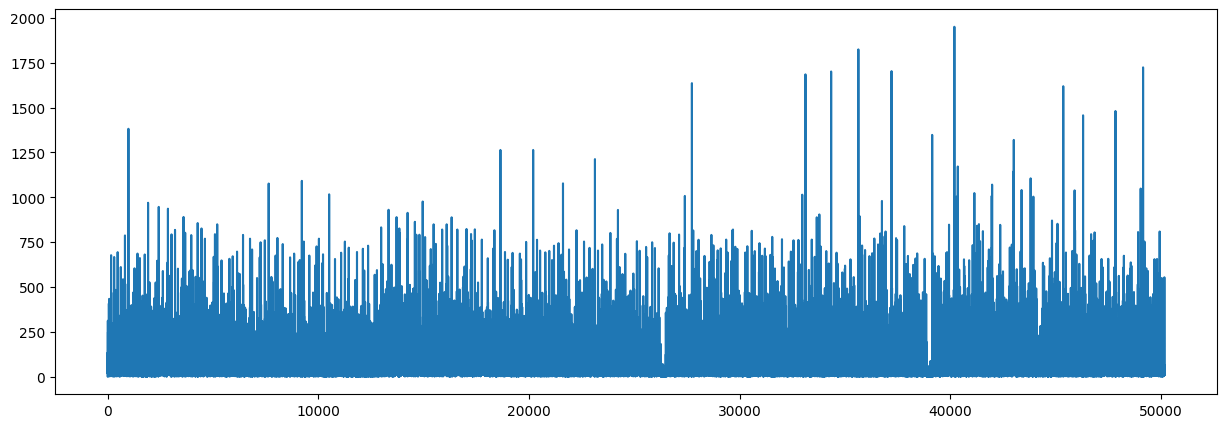

In [189]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [15, 5]
data_full.reset_index()["GesamtmengeVj"].plot()

In [ ]:
Produkte = data_full["Produkt"].drop_duplicates().to_list()
from scipy.stats import iqr
import numpy as np
for Produkt in Produkte:
    plt.figure()
    new_data = data_full.loc[(data_full['Produkt'] == Produkt)].reset_index()
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation = 'midpoint')
    new_data["GesamtmengeVj"].plot(title=Produkt)
    [plt.axvline(_x, linewidth=1, color='g') for _x in new_data.loc[(new_data['MittelwertSonderangebote'] == 1)].index.to_list()]
    plt.axhline(y=Q3 + 1.5 * IQR, color='r', linestyle='-')
    plt.axhline(y=Q3 - 1.5 * IQR, color='r', linestyle='-')
    plt.savefig('Plots/' + Produkt +'.pdf')

In [ ]:
Fettarme_Produkte = data_full_fettarm["Produkt"].drop_duplicates().to_list()
data_full_fettarm_high = pd.DataFrame(columns=data_full_fettarm.columns)
data_full_fettarm_high.index.name = 'Woche'
for Fettarmes_Produkt in Fettarme_Produkte:
    new_data = data_full_fettarm.loc[
        (data_full_fettarm["Produkt"] == Fettarmes_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettarm_high = pd.concat(
        [
            data_full_fettarm_high,
            new_data.loc[(new_data["GesamtmengeVj"] > (Q3 + 1.5 * IQR))],
        ]
    )
data_full_fettarm_high.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettarm_hoch.csv")

In [192]:
Fettarme_Produkte = data_full_fettarm["Produkt"].drop_duplicates().to_list()
data_full_fettarm_low_normal = pd.DataFrame(columns=data_full_fettarm.columns)
data_full_fettarm_low_normal.index.name = 'Woche'
for Fettarmes_Produkt in Fettarme_Produkte:
    new_data = data_full_fettarm.loc[
        (data_full_fettarm["Produkt"] == Fettarmes_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettarm_low_normal = pd.concat(
        [
            data_full_fettarm_low_normal,
            new_data.loc[(new_data["GesamtmengeVj"] <= (Q3 + 1.5 * IQR))],
        ]
    )
data_full_fettarm_low_normal.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettarm_niedrig_normal.csv")

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [193]:
Fettreiche_Produkte = data_full_fettreich["Produkt"].drop_duplicates().to_list()
data_full_fettreich_high = pd.DataFrame(columns=data_full_fettreich.columns)
data_full_fettreich_high.index.name = 'Woche'
for Fettreiches_Produkt in Fettreiche_Produkte:
    new_data = data_full_fettreich.loc[
        (data_full_fettreich["Produkt"] == Fettreiches_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettreich_high = pd.concat(
        [
            data_full_fettreich_high,
            new_data.loc[(new_data["GesamtmengeVj"] > (Q3 + 1.5 * IQR))],
        ]
    )
data_full_fettreich_high.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettreich_hoch.csv")

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [194]:
Fettreiche_Produkte = data_full_fettreich["Produkt"].drop_duplicates().to_list()
data_full_fettreich_low_normal = pd.DataFrame(columns=data_full_fettreich.columns)
data_full_fettreich_low_normal.index.name = 'Woche'
for Fettreiches_Produkt in Fettreiche_Produkte:
    new_data = data_full_fettreich.loc[
        (data_full_fettreich["Produkt"] == Fettreiches_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettreich_low_normal = pd.concat(
        [
            data_full_fettreich_low_normal,
            new_data.loc[(new_data["GesamtmengeVj"] <= (Q3 + 1.5 * IQR))],
        ]
    )
data_full_fettreich_low_normal.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettreich_niedrig_normal.csv")

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [195]:
Fettreiche_Produkte = data_full_fettreich["Produkt"].drop_duplicates().to_list()
data_full_fettreich_low = pd.DataFrame(columns=data_full_fettreich.columns)
data_full_fettreich_low.index.name = 'Woche'
for Fettreiches_Produkt in Fettreiche_Produkte:
    new_data = data_full_fettreich.loc[
        (data_full_fettreich["Produkt"] == Fettreiches_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettreich_low = pd.concat(
        [
            data_full_fettreich_low,
            new_data.loc[(new_data["GesamtmengeVj"] < (Q3 - 1.5 * IQR))],
        ]
    )
data_full_fettreich_low.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettreich_niedrig.csv")

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [196]:
Fettarme_Produkte = data_full_fettarm["Produkt"].drop_duplicates().to_list()
data_full_fettarm_low = pd.DataFrame(columns=data_full_fettarm.columns)
data_full_fettarm_low.index.name = 'Woche'
for Fettarmes_Produkt in Fettarme_Produkte:
    new_data = data_full_fettarm.loc[
        (data_full_fettarm["Produkt"] == Fettarmes_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettarm_low = pd.concat(
        [
            data_full_fettarm_low,
            new_data.loc[(new_data["GesamtmengeVj"] < (Q3 - 1.5 * IQR))],
        ]
    )
data_full_fettarm_low.to_csv("/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettarm_niedrig.csv")

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [197]:
Fettreiche_Produkte = data_full_fettreich["Produkt"].drop_duplicates().to_list()
data_full_fettreich_normal = pd.DataFrame(columns=data_full_fettreich.columns)
data_full_fettreich_normal.index.name = "Woche"
for Fettreiches_Produkt in Fettreiche_Produkte:
    new_data = data_full_fettreich.loc[
        (data_full_fettreich["Produkt"] == Fettreiches_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettreich_normal = pd.concat(
        [
            data_full_fettreich_normal,
            new_data.loc[
                (new_data["GesamtmengeVj"] >= (Q3 - 1.5 * IQR))
                & (new_data["GesamtmengeVj"] <= (Q3 + 1.5 * IQR))
            ],
        ]
    )
data_full_fettreich_normal.to_csv(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettreich_normal.csv"
)

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [199]:
Fettarme_Produkte = ["Produkt"].drop_duplicates().to_list()
data_full_fettarm_normal = pd.DataFrame(columns=data_full_fettarm.columns)
data_full_fettarm_normal.index.name = "Woche"
for Fettarmes_Produkt in Fettarme_Produkte:
    new_data = data_full_fettarm.loc[
        (data_full_fettarm["Produkt"] == Fettarmes_Produkt)
    ]
    IQR = iqr(new_data["GesamtmengeVj"])
    Q3 = np.percentile(new_data["GesamtmengeVj"], 75, interpolation="midpoint")
    data_full_fettarm_normal = pd.concat(
        [
            data_full_fettarm_normal,
            new_data.loc[
                (new_data["GesamtmengeVj"] >= (Q3 - 1.5 * IQR))
                & (new_data["GesamtmengeVj"] <= (Q3 + 1.5 * IQR))
            ],
        ]
    )
data_full_fettarm_normal.to_csv(
    "/Volumes/BITStorage/Workspace/Josef/01_Schreibtisch/05_Healthy food product purchase drives from sales data using machine learning/Datasets/Complete/Joghurt_20-23_fettarm_normal.csv"
)

AttributeError: 'list' object has no attribute 'drop_duplicates'